In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np

In [3]:
# Load World Happiness data (2015)
happiness_df = pd.read_csv("../../data/raw/2015.csv")

# Structural overview
print(f"Dataset shape: {happiness_df.shape}")
print("-" * 50)
happiness_df.info()

Dataset shape: (158, 12)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        158 non-null    object 
 1   Region                         158 non-null    object 
 2   Happiness Rank                 158 non-null    int64  
 3   Happiness Score                158 non-null    float64
 4   Standard Error                 158 non-null    float64
 5   Economy (GDP per Capita)       158 non-null    float64
 6   Family                         158 non-null    float64
 7   Health (Life Expectancy)       158 non-null    float64
 8   Freedom                        158 non-null    float64
 9   Trust (Government Corruption)  158 non-null    float64
 10  Generosity                     158 non-null    float64
 11  Dystopia Residual              158

In [4]:
happiness_df.isnull().sum()

Country                          0
Region                           0
Happiness Rank                   0
Happiness Score                  0
Standard Error                   0
Economy (GDP per Capita)         0
Family                           0
Health (Life Expectancy)         0
Freedom                          0
Trust (Government Corruption)    0
Generosity                       0
Dystopia Residual                0
dtype: int64

In [5]:
duplicated_values = happiness_df.duplicated()
duplicated_values.sum()


np.int64(0)

In [14]:
display(happiness_df.select_dtypes(include='number').describe().T)

,count,mean,std,min,25%,50%,75%,max
Happiness Rank,158.0,79.493671,45.754363,1.00000,40.250000,79.500000,118.750000,158.00000
Happiness Score,158.0,5.375734,1.145010,2.83900,4.526000,5.232500,6.243750,7.58700
Standard Error,158.0,0.047885,0.017146,0.01848,0.037268,0.043940,0.052300,0.13693
Economy (GDP per Capita),158.0,0.846137,0.403121,0.00000,0.545808,0.910245,1.158448,1.69042
Family,158.0,0.991046,0.272369,0.00000,0.856823,1.029510,1.214405,1.40223
Health (Life Expectancy),158.0,0.630259,0.247078,0.00000,0.439185,0.696705,0.811013,1.02525
Freedom,158.0,0.428615,0.150693,0.00000,0.328330,0.435515,0.549092,0.66973
Trust (Government Corruption),158.0,0.143422,0.120034,0.00000,0.061675,0.107220,0.180255,0.55191
Generosity,158.0,0.237296,0.126685,0.00000,0.150553,0.216130,0.309883,0.79588
Dystopia Residual,158.0,2.098977,0.553550,0.32858,1.759410,2.095415,2.462415,3.60214


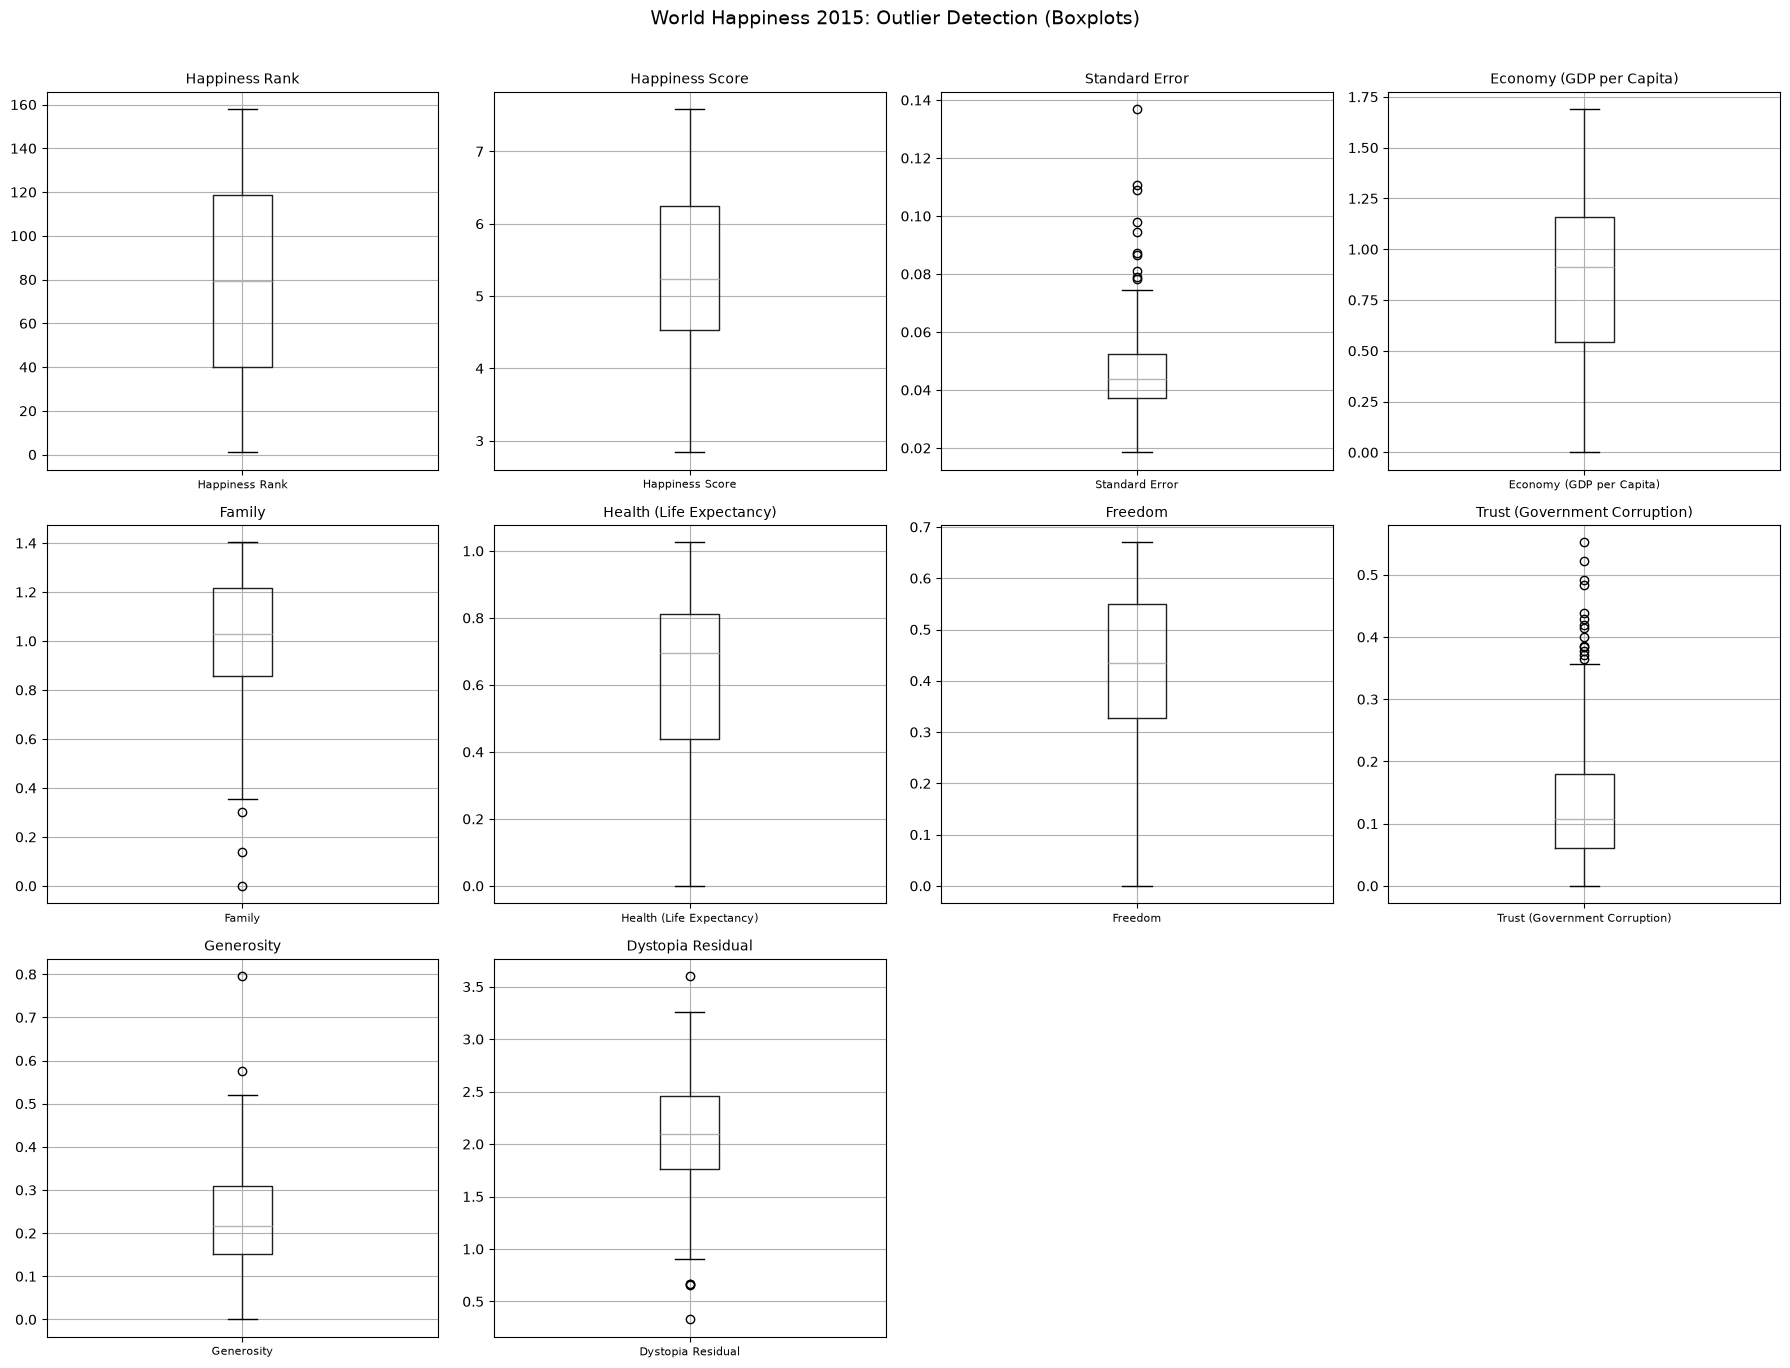

In [18]:


# Auto-detect all numeric columns in the dataset
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# Number of features to plot and grid layout
n = len(numeric_cols)
ncols = 4
nrows = math.ceil(n / ncols)   # number of rows needed based on the actual number of columns

# Create the figure and axes grid
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
axes = axes.flatten()

# Plot a boxplot for each numeric column
for i, col in enumerate(numeric_cols):
    happiness_df.boxplot(column=col, ax=axes[i], vert=True)
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis="x", labelsize=8)

# Hide ONLY the unused axes (when n is not a multiple of ncols)
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("World Happiness 2015: Outlier Detection (Boxplots)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

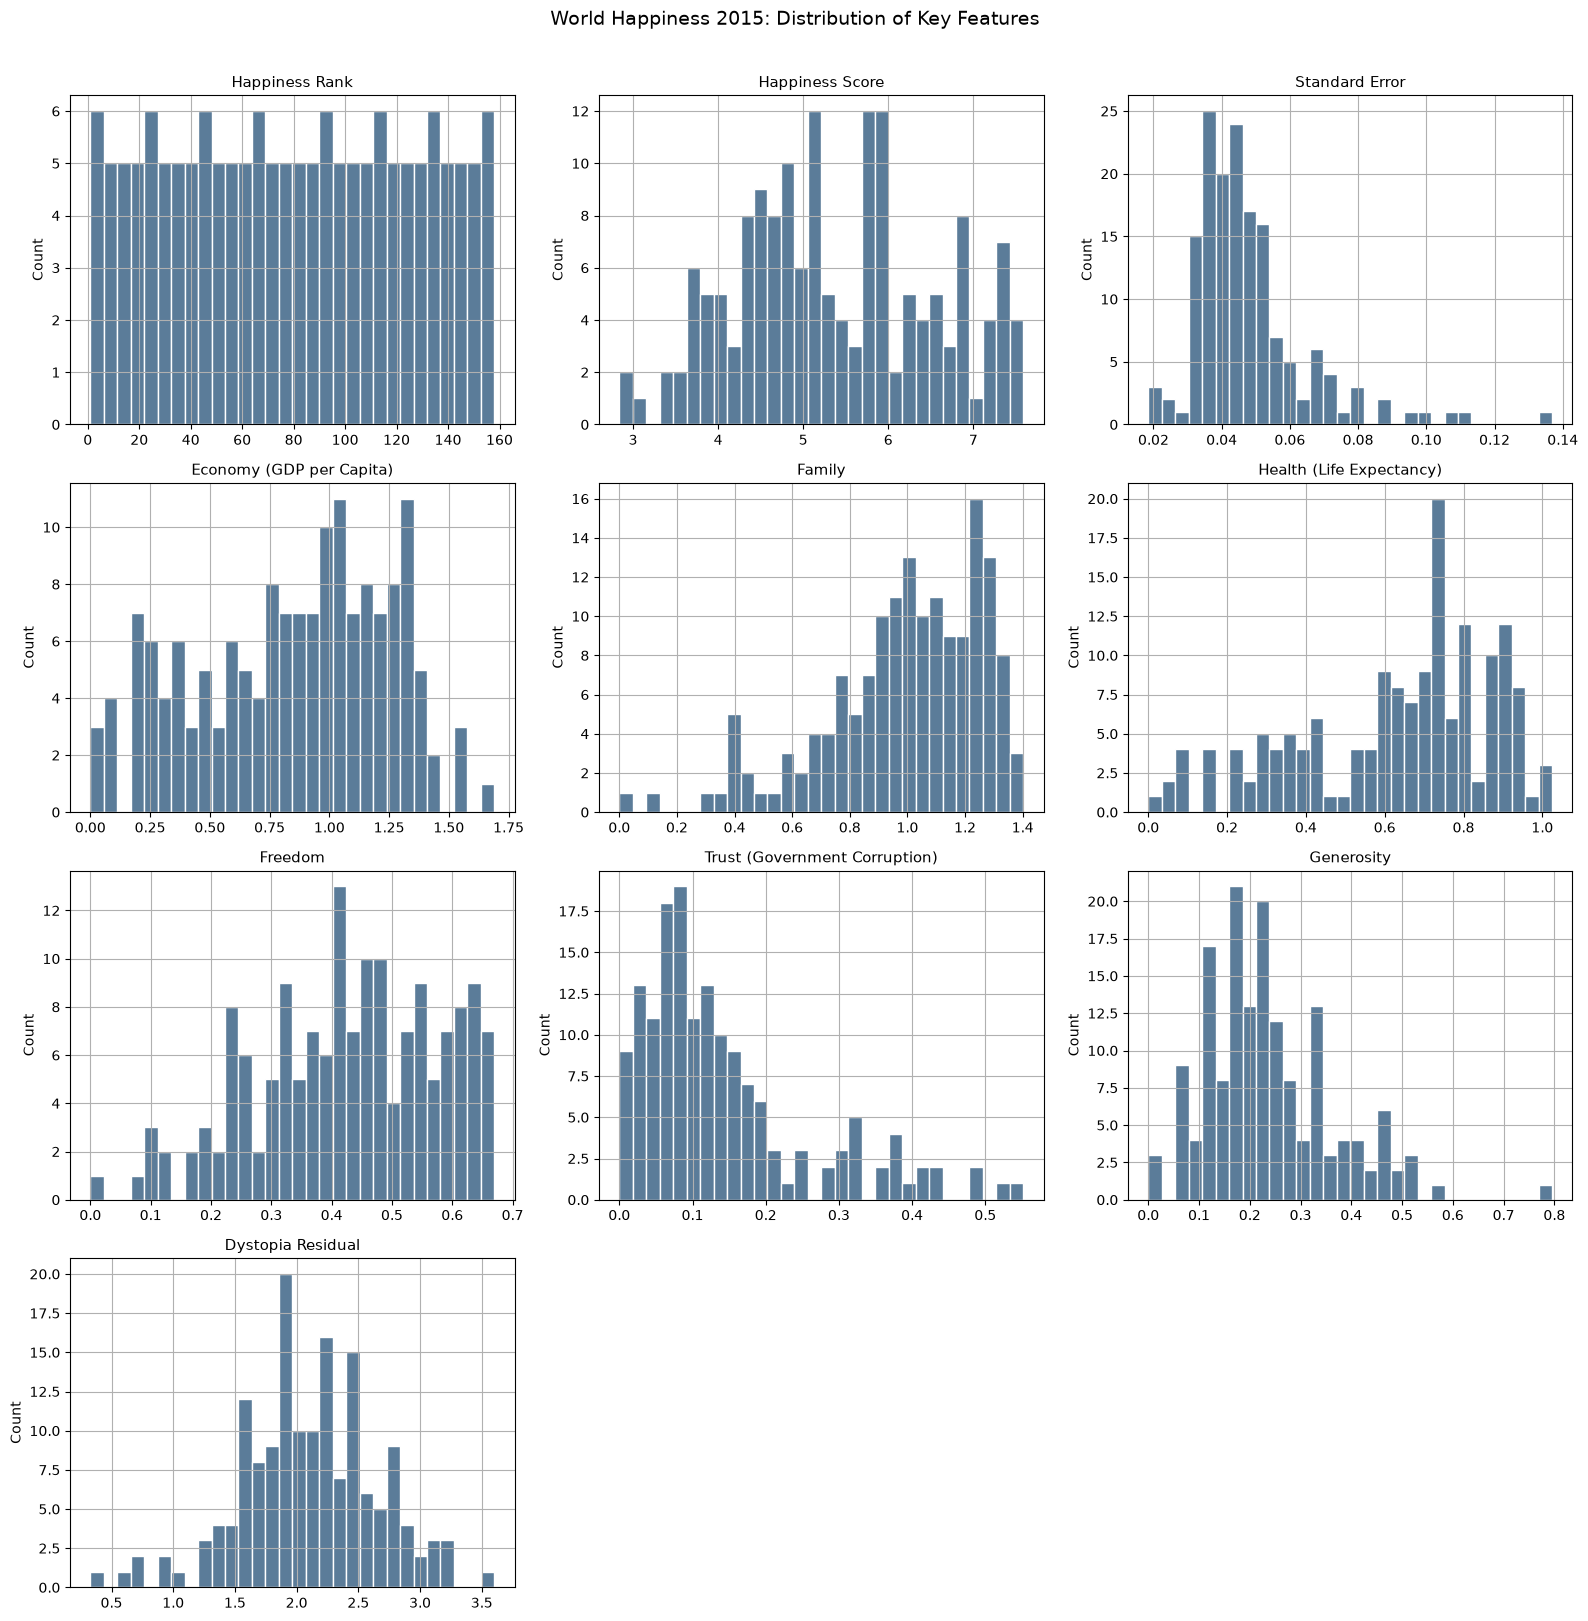

In [ ]:
# Auto-detect all numeric columns in the dataset
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# Number of features to plot and grid layout
n = len(numeric_cols)
ncols = 3
nrows = math.ceil(n / ncols)   # rows needed based on actual number of columns

# Create the figure and axes grid
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = axes.flatten()

# Plot a histogram for each numeric column
for i, col in enumerate(numeric_cols):
    happiness_df[col].hist(bins=30, ax=axes[i], color="#5b7c99", edgecolor="white")
    axes[i].set_title(col, fontsize=11)
    axes[i].set_ylabel("Count")

# Hide ONLY the unused axes (when n is not a multiple of ncols)
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("World Happiness 2015: Distribution of Key Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

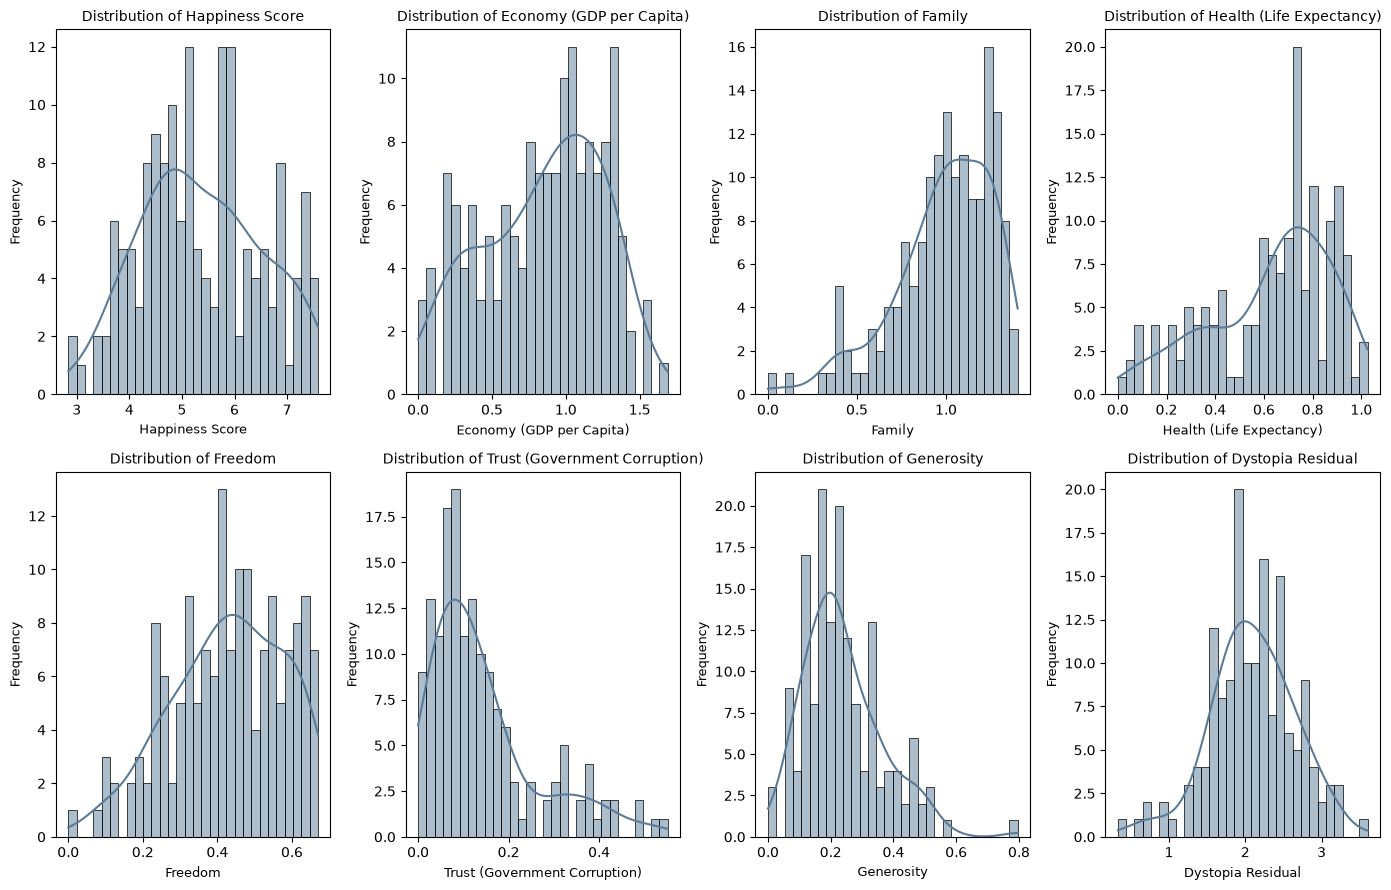

In [10]:
happiness_features = [
    "Happiness Score",
    "Economy (GDP per Capita)",
    "Family",
    "Health (Life Expectancy)",
    "Freedom",
    "Trust (Government Corruption)",
    "Generosity",
    "Dystopia Residual",
]

plt.figure(figsize=(14, 9))

for i, feature in enumerate(happiness_features, 1):
    plt.subplot(2, 4, i)

    sns.histplot(
        happiness_df[feature].dropna(),
        bins=30,
        kde=True,
        color="#5b7c99",
    )

    plt.title(f"Distribution of {feature}", fontsize=10)
    plt.xlabel(feature, fontsize=9)
    plt.ylabel("Frequency", fontsize=9)

plt.tight_layout()
plt.show()

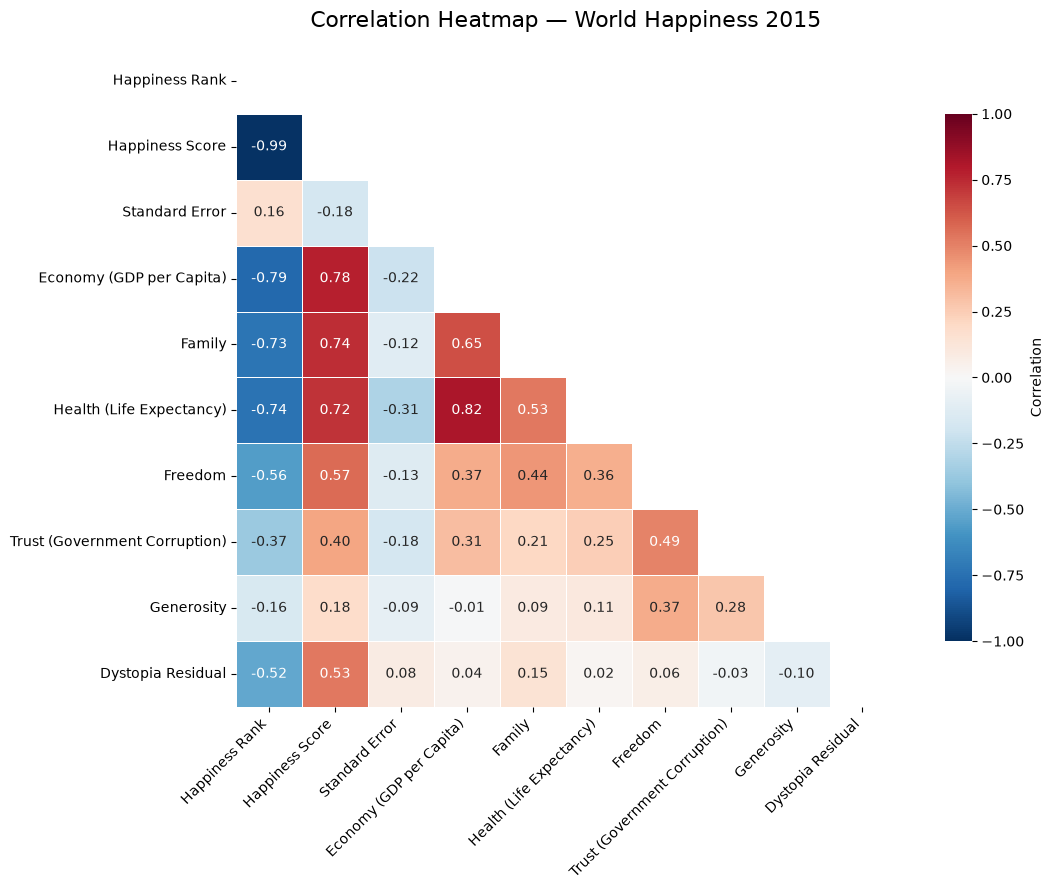

In [21]:

# Select numerical columns
numeric_df = happiness_df.select_dtypes(include="number")

# Calculate the correlation matrix
corr_matrix = numeric_df.corr()

# Create a mask to display only the lower triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Plot the heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Correlation"}
)

plt.title("Correlation Heatmap — World Happiness 2015", fontsize=16, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

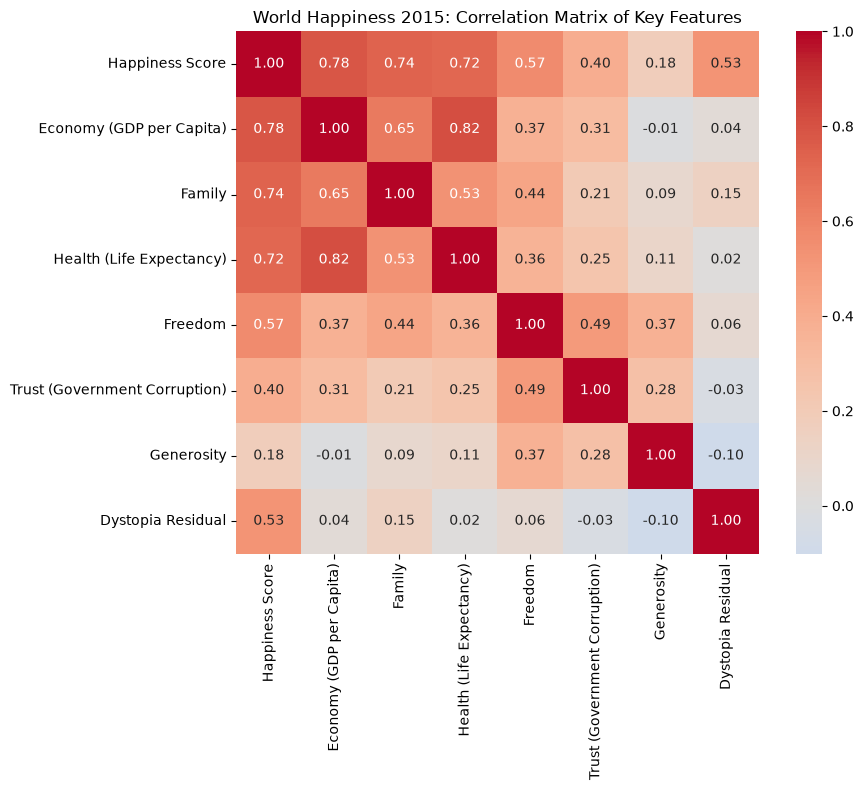

In [22]:


# Correlation heatmap of happiness features
happiness_features = [
    "Happiness Score",
    "Economy (GDP per Capita)",
    "Family",
    "Health (Life Expectancy)",
    "Freedom",
    "Trust (Government Corruption)",
    "Generosity",
    "Dystopia Residual",
]

fig, ax = plt.subplots(figsize=(10, 8))
corr = happiness_df[happiness_features].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, square=True)
ax.set_title("World Happiness 2015: Correlation Matrix of Key Features")
plt.tight_layout()
plt.show()